<a href="https://colab.research.google.com/github/xabierblanch/EGG_FotogrametriaTerrestre/blob/main/FMT_S6_RANSAC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RANSAC - Exercici pràctic

Quan busquem punts homòlegs entre dues fotos, una part de les parelles són **errònies** (outliers): objectes repetits, reflexos, zones sense textura... Si calculem un model (una homografia, la matriu fonamental $F$, la matriu essencial $E$) amb **totes** les parelles, els errors el fan inservible.

**RANSAC** (*RANdom SAmple Consensus*) resol aquest problema. En aquest notebook el programem nosaltres per calcular la matriu fonamental $F$ entre dues fotos d'una aula:

| Apartat | Contingut |
|---|---|
| **1** | Les fotos, el calibratge i les parelles d'homòlegs (SIFT) |
| **2** | El problema: $F$ amb totes les parelles |
| **3** | RANSAC programat pas a pas |
| **4** | Resultat i comparació amb OpenCV |

## 0.- Configuració de l'entorn

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

plt.rcParams['figure.dpi'] = 90
np.set_printoptions(precision=4, suppress=True)
RANDOM_SEED = 0


def load_rgb(path):
    return cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)


def to_homogeneous(points):
    return np.column_stack([points, np.ones(len(points))])


def draw_pairs(image_1, image_2, points_1, points_2, title, mask=None, max_lines=400):
    """Side-by-side photos with the pairs joined by lines.
    Without mask: every pair in a different colour. With mask: green = accepted, red = rejected."""
    rng = np.random.default_rng(RANDOM_SEED)
    width = image_1.shape[1]
    plt.figure(figsize=(18, 7)); plt.imshow(np.hstack([image_1, image_2]))
    groups = [(np.ones(len(points_1), bool), None, None)] if mask is None else [(~mask, 'red', 'rebutjades'), (mask, 'lime', 'acceptades')]
    for keep, color, label in groups:
        indices = np.flatnonzero(keep)
        for k in rng.choice(indices, min(max_lines, len(indices)), replace=False):
            plt.plot([points_1[k, 0], points_2[k, 0] + width], [points_1[k, 1], points_2[k, 1]], '-', lw=0.8,
                     color=color or rng.random(3))
        if label:
            plt.plot([], [], color=color, label=f"{label}: {keep.sum()}")
    if mask is not None:
        plt.legend(loc='lower right', fontsize=12)
    plt.title(title); plt.axis('off'); plt.show()


print("Entorn configurat correctament amb OpenCV", cv2.__version__)

Entorn configurat correctament amb OpenCV 4.14.0


## 1.- Les dades

### 1.1.- Les fotos de l'aula

Dues fotos de l'aula fetes des de dos llocs diferents. L'aula és un cas difícil per emparellar punts: hi ha **molts objectes repetits** (monitors, teclats, cadires) i parets blanques sense textura.

Falten aquests fitxers: ['aula_A.jpg', 'aula_B.jpg'] -> puja'ls ara


Saving aula_A.jpg to aula_A.jpg
Saving aula_B.jpg to aula_B.jpg


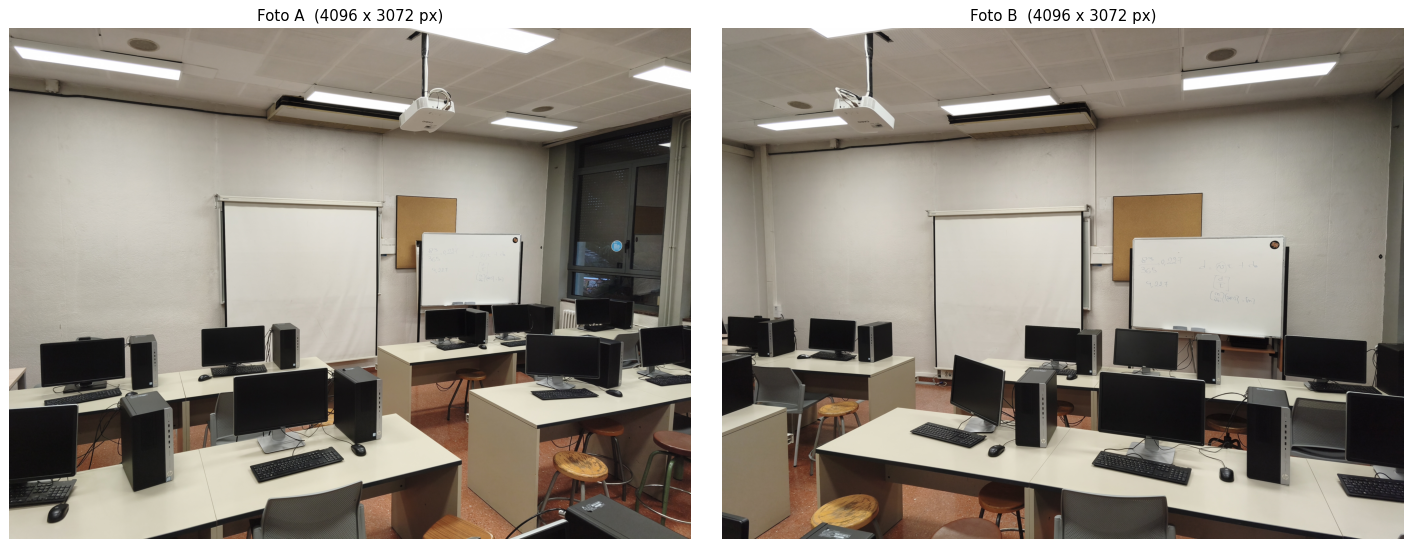

In [2]:
IMAGE_A_PATH, IMAGE_B_PATH = 'aula_A.jpg', 'aula_B.jpg'

missing_files = [p for p in (IMAGE_A_PATH, IMAGE_B_PATH) if not os.path.exists(p)]
if missing_files and IN_COLAB:
    print("Falten aquests fitxers:", missing_files, "-> puja'ls ara")
    files.upload()

image_A, image_B = load_rgb(IMAGE_A_PATH), load_rgb(IMAGE_B_PATH)
image_height, image_width = image_A.shape[:2]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, image, name in zip(axes, (image_A, image_B), ('A', 'B')):
    ax.imshow(image); ax.set_title(f"Foto {name}  ({image.shape[1]} x {image.shape[0]} px)"); ax.axis('off')
plt.tight_layout(); plt.show()

### 1.2.- El calibratge i la correcció de la distorsió

La geometria epipolar suposa el model pinhole: raigs rectes i, per tant, rectes epipolars rectes. La distorsió de la lent corba les rectes, i $F$ no la pot absorbir. Per això **corregim la distorsió** de les fotos amb els paràmetres interns del calibratge ($K$ i $\mathbf{d}$).

El calibratge es va fer amb el mòbil **en vertical** i aquestes fotos són **horitzontals**: les focals s'intercanvien ($f_x \leftrightarrow f_y$), el punt principal passa a $(c_y,\; W_{vertical} - 1 - c_x)$ i els coeficients tangencials també giren.

In [3]:
CALIBRATION_XML = 'camera_calibration.xml'

if not os.path.exists(CALIBRATION_XML) and IN_COLAB:
    print("Falta", CALIBRATION_XML, "-> puja'l ara")
    files.upload()

storage = cv2.FileStorage(CALIBRATION_XML, cv2.FILE_STORAGE_READ)
K_calibration = storage.getNode('camera_matrix').mat()
dist_calibration = storage.getNode('dist_coeffs').mat().ravel()
calibration_width, calibration_height = int(storage.getNode('image_width').real()), int(storage.getNode('image_height').real())
storage.release()

if (calibration_height > calibration_width) != (image_height > image_width):
    fx, fy, cx, cy = K_calibration[0, 0], K_calibration[1, 1], K_calibration[0, 2], K_calibration[1, 2]
    k1, k2, p1, p2, k3 = dist_calibration
    K = np.array([[fy, 0, cy], [0, fx, (calibration_width - 1) - cx], [0, 0, 1.0]])
    dist_coeffs = np.array([k1, k2, -p2, p1, k3])
    print("Calibratge vertical i fotos horitzontals: giro K i la distorsió.")
else:
    K, dist_coeffs = K_calibration.copy(), dist_calibration.copy()

print("K =\n", K.round(1))
print("d =", dist_coeffs.round(4))

undistorted_A = cv2.undistort(image_A, K, dist_coeffs, None, K)
undistorted_B = cv2.undistort(image_B, K, dist_coeffs, None, K)

Falta camera_calibration.xml -> puja'l ara


Saving camera_calibration.xml to camera_calibration.xml
Calibratge vertical i fotos horitzontals: giro K i la distorsió.
K =
 [[2750.3    0.  2020.7]
 [   0.  2763.5 1497. ]
 [   0.     0.     1. ]]
d = [ 0.0085  0.1484 -0.0021 -0.0031 -0.1872]


### 1.3.- Parelles d'homòlegs amb SIFT

Busquem homòlegs amb **SIFT**, amb dos filtres habituals: el *ratio test* de Lowe (el millor candidat ha de ser clarament millor que el segon) i la comprovació mútua (A→B i B→A han de coincidir).

Tot i aquests filtres, **moltes parelles continuaran sent errònies**. Mireu les línies: n'hi ha que creuen la imatge de manera absurda.

Parelles d'homòlegs trobades per SIFT: 380


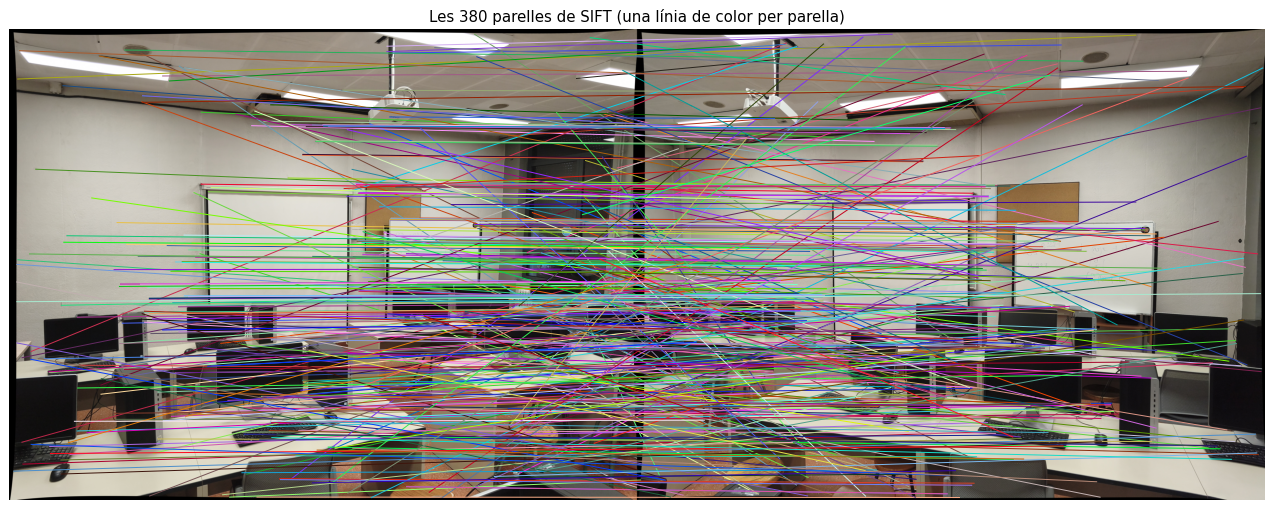

In [4]:
def detect_and_match(image_1, image_2, scale=0.75, ratio=0.75):
    """SIFT on a downscaled copy + Lowe ratio test + mutual check. Returns full-resolution pixel coordinates."""
    sift = cv2.SIFT_create(contrastThreshold=0.01)
    keypoints, descriptors = [], []
    for image in (image_1, image_2):
        small = cv2.resize(cv2.cvtColor(image, cv2.COLOR_RGB2GRAY), None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
        kp, desc = sift.detectAndCompute(small, None)
        keypoints.append(np.array([k.pt for k in kp]) / scale)
        descriptors.append(desc)
    matcher = cv2.BFMatcher(cv2.NORM_L2)
    knn = matcher.knnMatch(descriptors[0], descriptors[1], k=2)
    reverse = {m.queryIdx: m.trainIdx for m in matcher.match(descriptors[1], descriptors[0])}
    good = [m for m, n in knn if m.distance < ratio * n.distance and reverse.get(m.trainIdx) == m.queryIdx]
    return np.array([keypoints[0][m.queryIdx] for m in good]), np.array([keypoints[1][m.trainIdx] for m in good])


matches_A, matches_B = detect_and_match(undistorted_A, undistorted_B)
print(f"Parelles d'homòlegs trobades per SIFT: {len(matches_A)}")
draw_pairs(undistorted_A, undistorted_B, matches_A, matches_B, f"Les {len(matches_A)} parelles de SIFT (una línia de color per parella)")

## 2.- El problema: $F$ amb totes les parelles

### 2.1.- Les eines: calcular $F$ i mesurar l'error d'una parella

**Calcular F.** Fem servir l'**algorisme dels 8 punts normalitzat** de la geometria epipolar: cada parella dona una equació $\mathbf{x}_B^T F \mathbf{x}_A = 0$, s'apilen en un sistema $A\,\mathbf{f} = 0$ i es resol amb la SVD. Amb 8 parelles n'hi ha prou; amb més, es resol per mínims quadrats.

**Error d'una parella.** Si $F$ és correcta, el punt $\mathbf{x}_B$ ha de ser sobre la recta epipolar $F\mathbf{x}_A$ (i $\mathbf{x}_A$ sobre $F^T\mathbf{x}_B$). Mesurem la distància en píxels i en fem la mitjana a les dues fotos:

$$d = \tfrac{1}{2}\left( d(\mathbf{x}_B,\, F\mathbf{x}_A) + d(\mathbf{x}_A,\, F^T\mathbf{x}_B) \right)$$

Una parella correcta té $d$ d'un píxel o menys; una parella errònia, desenes o centenars de píxels.

In [5]:
def normalization_matrix(points):
    centroid = points.mean(axis=0)
    scale = np.sqrt(2) / np.linalg.norm(points - centroid, axis=1).mean()
    return np.array([[scale, 0, -scale * centroid[0]], [0, scale, -scale * centroid[1]], [0, 0, 1]])


def fundamental_8point(points_A, points_B):
    """Normalized 8-point algorithm: normalize, solve A·f = 0 with SVD, force rank 2, denormalize."""
    T_A, T_B = normalization_matrix(points_A), normalization_matrix(points_B)
    a, b = (T_A @ to_homogeneous(points_A).T).T, (T_B @ to_homogeneous(points_B).T).T
    A_system = np.column_stack([b[:, 0] * a[:, 0], b[:, 0] * a[:, 1], b[:, 0], b[:, 1] * a[:, 0], b[:, 1] * a[:, 1], b[:, 1],
                                a[:, 0], a[:, 1], np.ones(len(a))])
    F_normalized = np.linalg.svd(A_system)[2][-1].reshape(3, 3)
    U, S, Vt = np.linalg.svd(F_normalized)
    F_pixels = T_B.T @ (U @ np.diag([S[0], S[1], 0]) @ Vt) @ T_A
    return F_pixels / np.linalg.norm(F_pixels)


def epipolar_distance(F_matrix, points_A, points_B):
    """Symmetric distance (px) of each pair to its epipolar lines."""
    lines_B = (F_matrix @ to_homogeneous(points_A).T).T            # l_B = F·x_A
    lines_A = (F_matrix.T @ to_homogeneous(points_B).T).T          # l_A = Fᵀ·x_B
    distance = lambda p, l: np.abs(l[:, 0] * p[:, 0] + l[:, 1] * p[:, 1] + l[:, 2]) / np.hypot(l[:, 0], l[:, 1])
    return 0.5 * (distance(points_B, lines_B) + distance(points_A, lines_A))

### 2.2.- Què passa si calculem $F$ amb totes les parelles?

Calculem $F$ amb **totes** les parelles de SIFT, sense filtrar, i mirem la distància de cada parella a la seva recta epipolar.

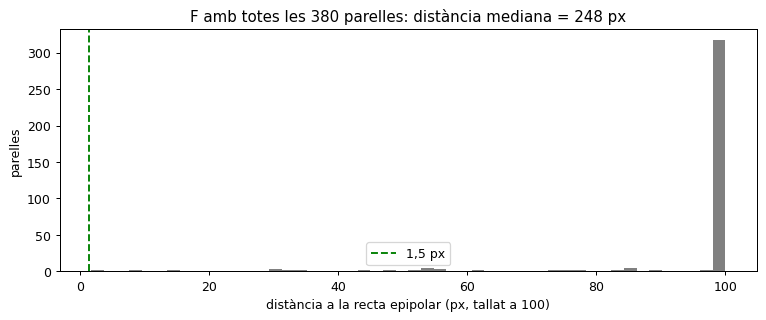

Parelles a menys de 1,5 px de la seva recta: 0 de 380


In [6]:
F_all_pairs = fundamental_8point(matches_A, matches_B)
distances_all = epipolar_distance(F_all_pairs, matches_A, matches_B)

plt.figure(figsize=(10, 3.5))
plt.hist(np.clip(distances_all, 0, 100), bins=50, color='gray')
plt.axvline(1.5, color='green', ls='--', label='1,5 px')
plt.xlabel("distància a la recta epipolar (px, tallat a 100)"); plt.ylabel("parelles"); plt.legend()
plt.title(f"F amb totes les {len(matches_A)} parelles: distància mediana = {np.median(distances_all):.0f} px"); plt.show()
print(f"Parelles a menys de 1,5 px de la seva recta: {(distances_all < 1.5).sum()} de {len(matches_A)}")

La $F$ calculada amb totes les parelles **no serveix per a ningú**: els outliers "estiren" la solució de mínims quadrats i ni les parelles bones queden a prop de la seva recta.

**L'ou i la gallina:** per calcular una bona $F$ necessitem saber quines parelles són bones, però per saber quines són bones necessitem una bona $F$. RANSAC trenca aquest cercle.

## 3.- RANSAC

### 3.1.- La idea

1. Triar **a l'atzar el mínim** de parelles per calcular el model: **8** per a $F$.
2. Calcular $F$ només amb aquestes 8 parelles.
3. Calcular la distància de **totes** les parelles a la seva recta i comptar les que queden per sota d'un **llindar** (1,5 px): són les parelles que "estan d'acord" amb aquesta $F$ (**inliers**).
4. Repetir $N$ vegades i quedar-se la $F$ amb **més inliers** (el *consens*).
5. Recalcular $F$ amb **tots** els inliers d'aquesta millor $F$.

**Per què funciona?** Si les 8 parelles de la mostra són totes bones, la $F$ que en surt és la correcta, i totes les parelles bones hi estaran d'acord. Si la mostra té alguna parella dolenta, la $F$ és dolenta i gairebé ningú hi està d'acord.

### 3.2.- Una mostra dolenta i una de bona

Abans de programar el bucle, mirem què passa amb **una sola mostra**. Provem dues mostres de 8 parelles i comptem quantes parelles accepta la $F$ de cadascuna.

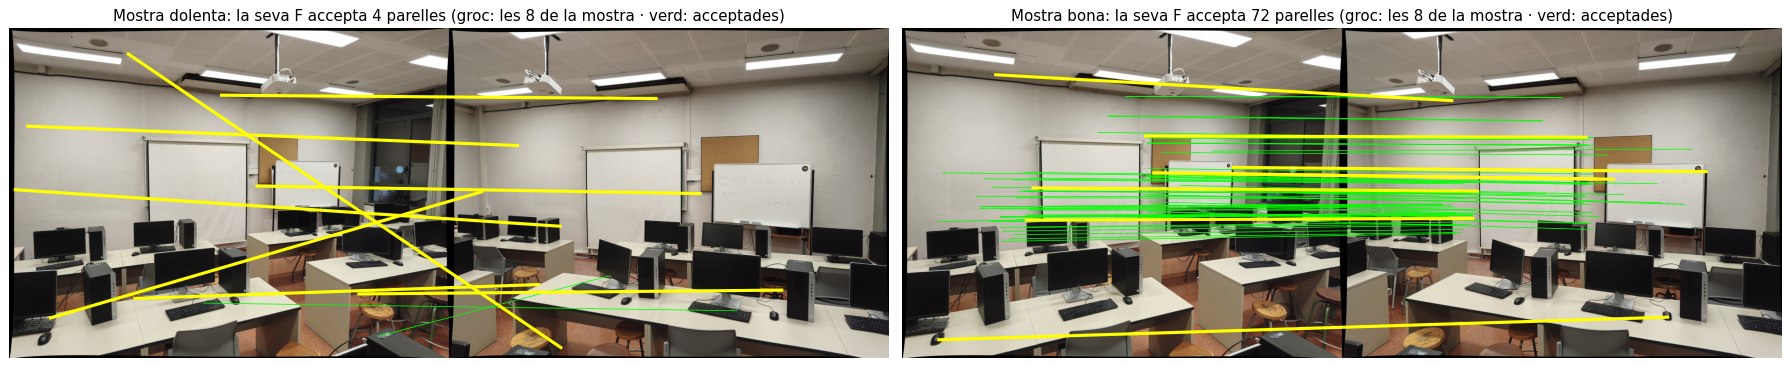

In [7]:
INLIER_THRESHOLD_PX = 1.5
rng = np.random.default_rng(RANDOM_SEED)

samples = {}
for attempt in range(5000):                          # look for one bad sample and one good sample
    sample = rng.choice(len(matches_A), size=8, replace=False)
    n_inliers = (epipolar_distance(fundamental_8point(matches_A[sample], matches_B[sample]), matches_A, matches_B) < INLIER_THRESHOLD_PX).sum()
    if 'dolenta' not in samples and n_inliers < 15:
        samples['dolenta'] = (sample, n_inliers)
    if n_inliers > samples.get('bona', (None, 0))[1]:
        samples['bona'] = (sample, n_inliers)

width = undistorted_A.shape[1]
fig, axes = plt.subplots(1, 2, figsize=(20, 5.5))
for ax, name in zip(axes, ('dolenta', 'bona')):
    sample, n_inliers = samples[name]
    F_sample = fundamental_8point(matches_A[sample], matches_B[sample])
    inliers = epipolar_distance(F_sample, matches_A, matches_B) < INLIER_THRESHOLD_PX
    ax.imshow(np.hstack([undistorted_A, undistorted_B]))
    for p, q in zip(matches_A[inliers], matches_B[inliers]):
        ax.plot([p[0], q[0] + width], [p[1], q[1]], '-', color='lime', lw=0.6)
    for p, q in zip(matches_A[sample], matches_B[sample]):
        ax.plot([p[0], q[0] + width], [p[1], q[1]], '-', color='yellow', lw=2.5)
    ax.set_title(f"Mostra {name}: la seva F accepta {n_inliers} parelles (groc: les 8 de la mostra · verd: acceptades)")
    ax.axis('off')
plt.tight_layout(); plt.show()

### 3.3.- RANSAC Manual

Elaborem el filtre RANSAC (manualment)

  intent     0: nova millor F, accepta    4 parelles de 380
  intent     3: nova millor F, accepta    5 parelles de 380
  intent    36: nova millor F, accepta   10 parelles de 380
  intent    42: nova millor F, accepta   27 parelles de 380
  intent    58: nova millor F, accepta   41 parelles de 380
  intent   238: nova millor F, accepta   52 parelles de 380
  intent   551: nova millor F, accepta   72 parelles de 380
  intent  6620: nova millor F, accepta   78 parelles de 380
  intent  9178: nova millor F, accepta   83 parelles de 380
  intent 14876: nova millor F, accepta   99 parelles de 380

Resultat (després del pas 5): 107 de 380 parelles (28%)


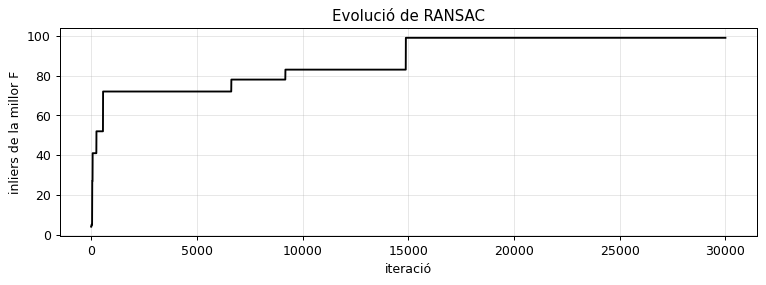

In [8]:
N_ITERATIONS = 30000


def ransac_fundamental(points_A, points_B, threshold_px, n_iterations, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    best_inliers = np.zeros(len(points_A), dtype=bool)
    history = []
    for iteration in range(n_iterations):
        sample = rng.choice(len(points_A), size=8, replace=False)                 # 1. 8 random pairs
        F_candidate = fundamental_8point(points_A[sample], points_B[sample])     # 2. F of the sample
        inliers = epipolar_distance(F_candidate, points_A, points_B) < threshold_px   # 3. pairs that agree
        if inliers.sum() > best_inliers.sum():                                   # 4. keep the best F
            best_inliers = inliers
            print(f"  intent {iteration:5d}: nova millor F, accepta {inliers.sum():4d} parelles de {len(points_A)}")
        history.append(best_inliers.sum())
    F_refined = fundamental_8point(points_A[best_inliers], points_B[best_inliers])   # 5. refit with all inliers
    final_inliers = epipolar_distance(F_refined, points_A, points_B) < threshold_px
    return F_refined, final_inliers, history


F_ransac, ransac_inliers, ransac_history = ransac_fundamental(matches_A, matches_B, INLIER_THRESHOLD_PX, N_ITERATIONS)
print(f"\nResultat (després del pas 5): {ransac_inliers.sum()} de {len(matches_A)} parelles ({ransac_inliers.mean():.0%})")

plt.figure(figsize=(10, 3)); plt.plot(ransac_history, color='black')
plt.xlabel("iteració"); plt.ylabel("inliers de la millor F"); plt.title("Evolució de RANSAC"); plt.grid(alpha=0.3); plt.show()

La gràfica puja a esglaons: cada esglaó és una mostra que ha donat una $F$ millor que totes les anteriors. Al principi en troba sovint; després cada vegada costa més, perquè cal tenir la sort de triar 8 parelles bones.

## 4.- Resultat

### 4.1.- Parelles acceptades i rebutjades

Verd: les parelles que compleixen la $F$ de RANSAC. Vermell: les rebutjades. Fixeu-vos on són les vermelles: sobretot als objectes repetits.

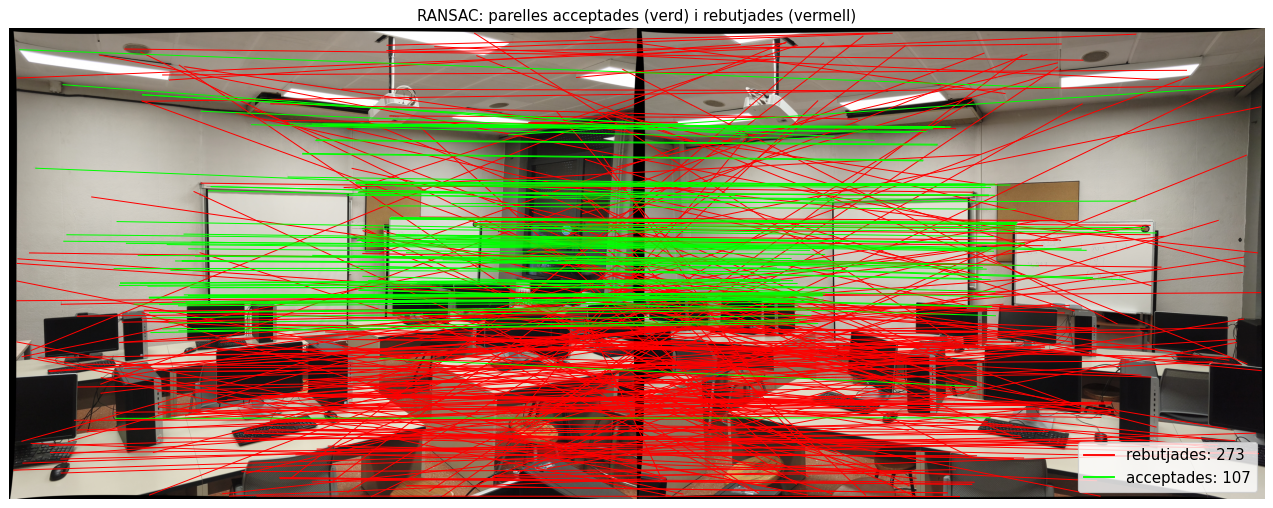

Distància mediana dels inliers a la seva recta: 0.36 px (amb F de totes les parelles: 248 px)


In [9]:
draw_pairs(undistorted_A, undistorted_B, matches_A, matches_B, "RANSAC: parelles acceptades (verd) i rebutjades (vermell)", mask=ransac_inliers)

distances_ransac = epipolar_distance(F_ransac, matches_A, matches_B)
print(f"Distància mediana dels inliers a la seva recta: {np.median(distances_ransac[ransac_inliers]):.2f} px "
      f"(amb F de totes les parelles: {np.median(distances_all):.0f} px)")

### 4.2.- Comparació amb OpenCV

A la pràctica no cal programar RANSAC: `cv2.findFundamentalMat` el porta incorporat (i també `cv2.findHomography` i `cv2.findEssentialMat`). OpenCV no fa un nombre fix d'iteracions: el calcula amb la fórmula de l'apartat 3.3, fent servir la millor fracció d'inliers trobada fins al moment, i para quan arriba a la probabilitat demanada (`confidence`). Amb tants outliers cal demanar una probabilitat alta (0,9999) i permetre moltes iteracions (`maxIters`); amb els valors per defecte para massa aviat i troba menys inliers.

In [10]:
cv2.setRNGSeed(RANDOM_SEED)
F_opencv, opencv_mask = cv2.findFundamentalMat(matches_A, matches_B, cv2.FM_RANSAC, INLIER_THRESHOLD_PX, confidence=0.9999, maxIters=100000)
opencv_inliers = opencv_mask.ravel().astype(bool)

print(f"Inliers del nostre RANSAC: {ransac_inliers.sum()}")
print(f"Inliers del RANSAC d'OpenCV: {opencv_inliers.sum()}")
print(f"En comú: {(ransac_inliers & opencv_inliers).sum()}")

Inliers del nostre RANSAC: 107
Inliers del RANSAC d'OpenCV: 103
En comú: 98


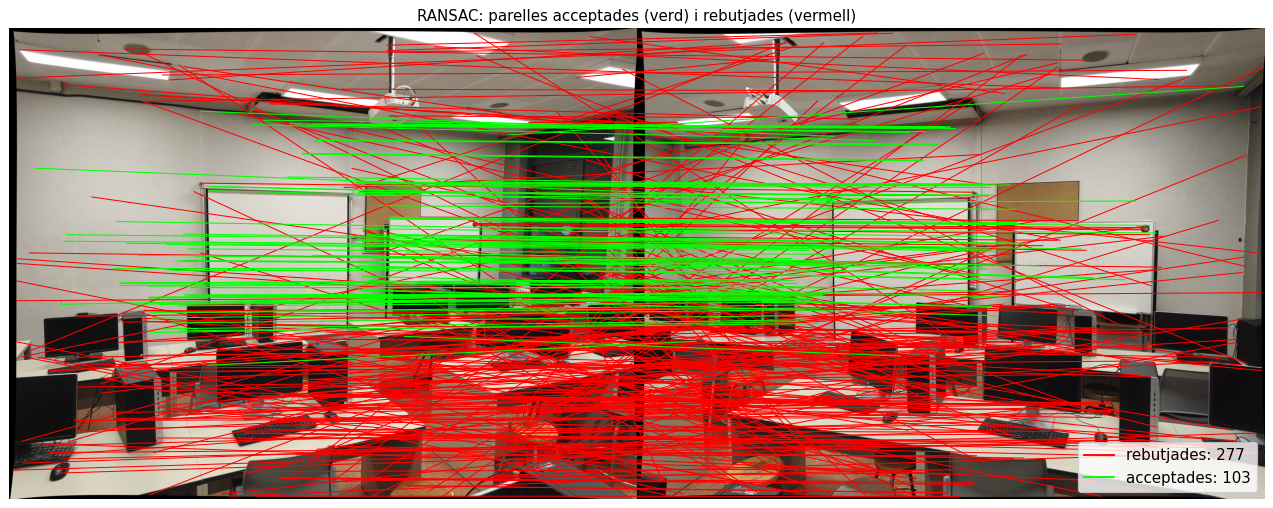

Distància mediana dels inliers a la seva recta: 0.33 px (amb F de totes les parelles: 248 px)


In [12]:
draw_pairs(undistorted_A, undistorted_B, matches_A, matches_B, "RANSAC: parelles acceptades (verd) i rebutjades (vermell)", mask=opencv_inliers)

distances_ransac = epipolar_distance(F_opencv, matches_A, matches_B)
print(f"Distància mediana dels inliers a la seva recta: {np.median(distances_ransac[opencv_inliers]):.2f} px "
      f"(amb F de totes les parelles: {np.median(distances_all):.0f} px)")